In [ ]:
# importing required libraries and loading dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/amazon_cleaned.csv", parse_dates=['Date'])
rev = df[(~df['is_cancelled']) & (df['Amount'].notna())]   # revenue rule, is_cancelled=Fales and Amount is notnull

def save(name): # to save the chart images
    plt.tight_layout()
    plt.savefig(f"../images/{name}.png", dpi=150)
    plt.show()

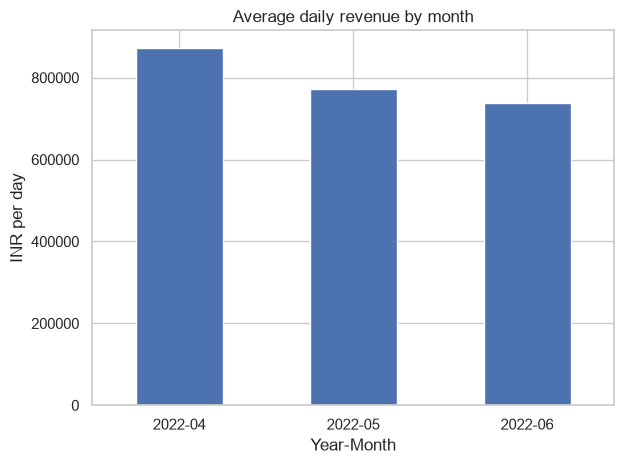

In [2]:
# average daily revenue by month
days = {'2022-04': 30, '2022-05': 31, '2022-06': 29}
monthly = rev[rev['Month'] >= 4].groupby('Year-Month')['Amount'].sum()
(monthly / pd.Series(days)).plot(kind='bar', rot=0)
plt.title('Average daily revenue by month'); plt.ylabel('INR per day')
save('monthly_daily_revenue')

April to June only, because March has one day and June ends on the 29th<br>it fell from about 800000+ a day in April to about 700000+ in May and 700000 in June, roughly 15% lower than April.

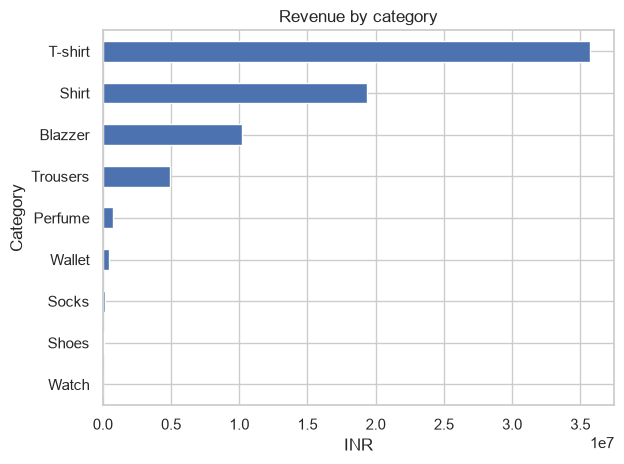

In [3]:
# revenue by category
rev.groupby('Category')['Amount'].sum().sort_values().plot(kind='barh')
plt.title('Revenue by category'); plt.xlabel('INR')
save('revenue_category')

T-shirts and shirts bring in most of the revenue, and shoes and watches contribute almost nothing. Compute the exact share of the top two.

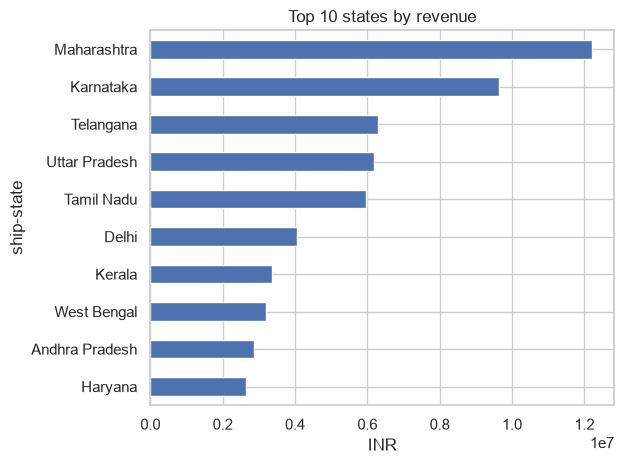

In [4]:
# top 10 states by revenue
rev[rev['ship-state'] != 'Unknown'].groupby('ship-state')['Amount'].sum().nlargest(10).sort_values().plot(kind='barh')
plt.title('Top 10 states by revenue'); plt.xlabel('INR')
save('revenue_state')

Maharashtra and Karnataka lead by a wide margin, followed by Telangana, Uttar Pradesh and Tamil Nadu.

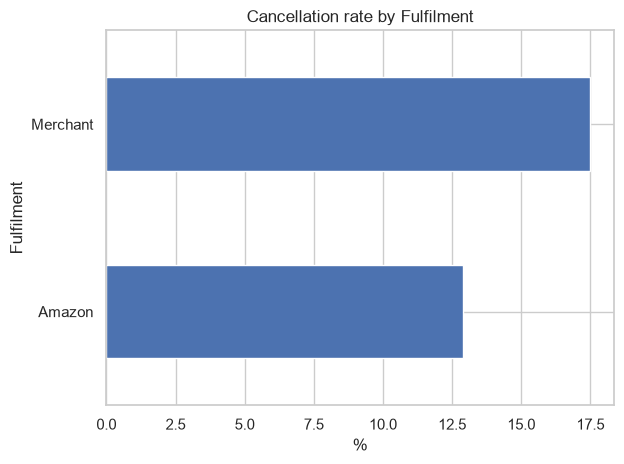

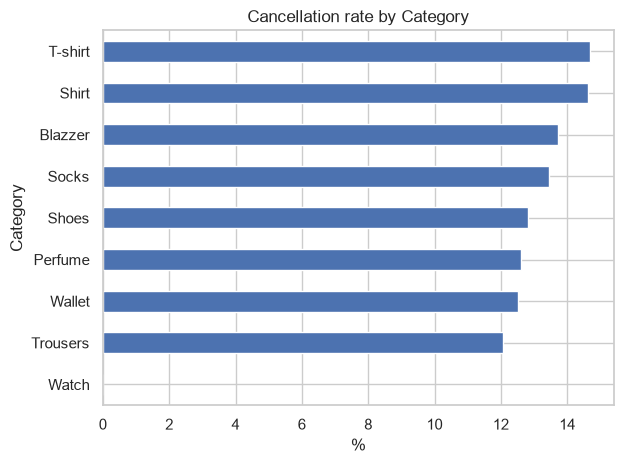

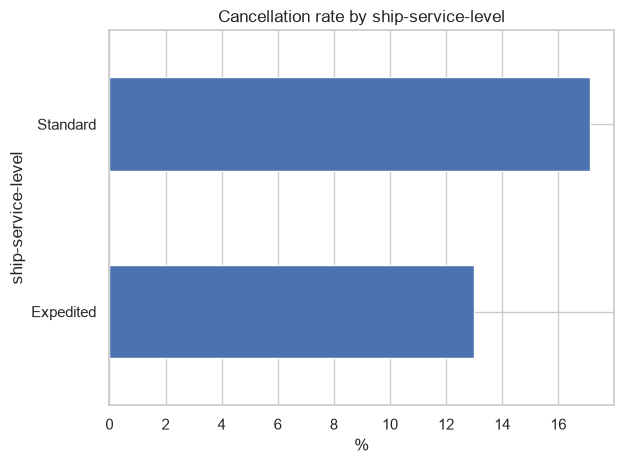

In [5]:
# cancellation rate by fulfilment, category and service level
for col in ['Fulfilment', 'Category', 'ship-service-level']:
    (df.groupby(col)['is_cancelled'].mean().sort_values() * 100).plot(kind='barh')
    plt.title(f'Cancellation rate by {col}'); plt.xlabel('%')
    save(f'cancel_{col}')

Merchant orders are cancelled about 17.5% of the time versus about 13% for Amazon-fulfilled orders.<br>
Standard shipping is cancelled about 17% versus about 13% for Expedited.<br>Merchant orders were Standard and Amazon orders were Expedited.<br>all categories in between about 12% and 15%, so product type isn't a strong driver.

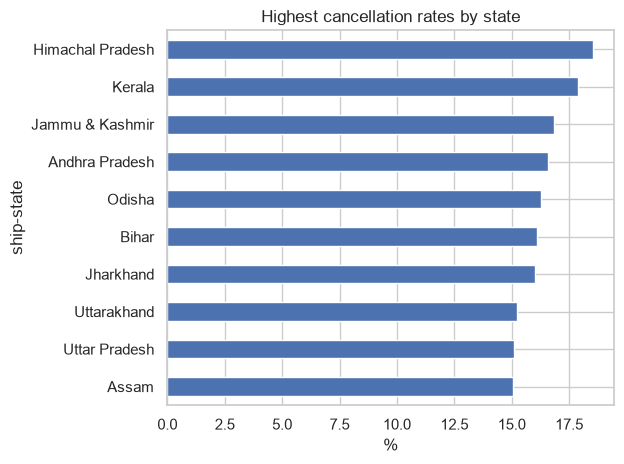

In [8]:
# cancellation rate by state (states with 500+ orders)
g = df.groupby('ship-state')['is_cancelled'].agg(['mean', 'count'])
g = g[g['count'] >= 500]
(g['mean'] * 100).sort_values().tail(10).plot(kind='barh')
plt.title('Highest cancellation rates by state'); plt.xlabel('%')
save('cancel_state')

the top ten range from about 15% to 18.5% (Himachal Pradesh and Kerala highest) against 14.3% overall. These are modest differences.

In [9]:
print("Overall cancellation rate:", round(df['is_cancelled'].mean() * 100, 1), "%")
print("Return rate:", round(df['Status'].str.contains('Returned').mean() * 100, 1), "%")
infl = df[df['is_cancelled']]['Amount'].sum() / df['Amount'].sum() * 100
print(f"Cancelled orders hold {infl:.1f}% of total Amount")

Overall cancellation rate: 14.3 %
Return rate: 1.5 %
Cancelled orders hold 8.8% of total Amount
